# Bosch production line: missingness, production routes, and defect screening

A CRISP-DM refactor of the original numeric-sensor investigation. The original notebook and its saved outputs are preserved in [archive/explore_original.ipynb](archive/explore_original.ipynb).

**Evidence status:** the archived 56-cell notebook preserves the original analyses, model code and saved historical outputs. This refactor retains the two model families, coverage-based sensor selection, station counts, station-combination definition, threshold/capacity comparisons and hyperparameter grid. New evaluation follows an explicit training-only selection procedure; historical scores are not silently reused.

**Run scope:** the setup output below identifies the actual executed population. A prefix run is a software smoke test, not a representative sample or a portfolio performance estimate. Default execution reads the full dataset; see README for a bounded smoke run. No split of these previously explored rows is called an untouched holdout.

## 1. Business Understanding

Can sensor availability and measurements help prioritize manufactured parts for defect inspection? One row is one part (`Id`); the positive class is `Response = 1` (defective). The operational example is inspecting the highest-risk **1%** of parts. This is an illustrative capacity, not a verified factory requirement.

The original data contain about 0.58% positives, so a model predicting every part as good would have impressive accuracy but detect no defects. We compare Average Precision (AP), precision, recall, confusion matrices, and gains/lift. Actual inspection costs and avoided defect costs are unavailable, so we do not invent profit or deployment benefits.

Assumption: all included measurements would be available at the intended screening point. Without process timing or domain confirmation, station availability may reflect rework or downstream inspection. That potential operational leakage remains unresolved.

### Setup and fixed experiment specification

Run from the project directory with the Bosch environment. `BOSCH_DATA_PATH` overrides the CSV location. `BOSCH_NROWS=20000` runs only the first 20,000 rows for verification; `0` (default) reads all rows. Close other large notebooks before a full run: the original float32 frame alone used 4.28 GiB, and CSV parsing/model fitting require additional memory.

The seed, feature budget, candidate models, threshold grid and capacities are declared before evaluation. `S32_only` retains its original definition: at least one S32 measurement and no S33 measurement. Like the original model cells, all default candidates exclude it because it was motivated by full-data target exploration. Set `INCLUDE_S32_ABLATION=True` only for a separately labeled exploratory ablation.

In [1]:
import hashlib
import json
import os
import platform
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import average_precision_score, precision_recall_curve
from threadpoolctl import threadpool_limits

from bosch import (
    availability_differences, build_features, capacity_metrics,
    classification_metrics, compare_models, gains_curve, load_numeric,
    missingness_profile, model_candidates, resolve_data_path, select_sensors,
    split_rows, station_columns, threshold_table, select_training_sensors,
)

ROOT = Path.cwd()
if not (ROOT / 'bosch.py').is_file():
    raise RuntimeError('Run this notebook from the Bosch project directory.')
SEED = 42
N_ROWS = int(os.environ.get('BOSCH_NROWS', '0')) or None
if N_ROWS is not None and N_ROWS < 1:
    raise ValueError('BOSCH_NROWS must be zero (full data) or positive.')
TOP_N_SENSORS = 20
S32_ABSENT_STATIONS = ('L3_S33',)
INCLUDE_S32_ABLATION = False
THRESHOLDS = (0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 0.6, 0.7, 0.8, 0.9)
CAPACITIES = (0.005, 0.01, 0.02, 0.05, 0.1)
PRIMARY_CAPACITY = 0.01
DATA_PATH = resolve_data_path(os.environ.get('BOSCH_DATA_PATH'))
RUN_SCOPE = 'full numeric dataset' if N_ROWS is None else f'prefix smoke test: first {N_ROWS:,} rows'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = ROOT / 'artifacts' / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('EXECUTED SCOPE:', RUN_SCOPE)
print('S32_only generated: S32 present and S33 absent; model ablation:', INCLUDE_S32_ABLATION)
print('Artifacts:', RUN_DIR.relative_to(ROOT))

EXECUTED SCOPE: prefix smoke test: first 20,000 rows
S32_only generated: S32 present and S33 absent; model ablation: False
Artifacts: artifacts/20261029T125911739576Z


## 2. Data Understanding

The saved original shape was **1,183,747 rows × 970 columns**: 968 sensors plus `Id` and `Response`. These are historical full-data facts; the displayed results below describe this run only. Sensor names encode line and station. Blank fields remain `NaN`; zero is a recorded value and must not be treated as missing.

The existing loading policy is retained: sensors use `float32`, identifiers `int64`, labels `int8`. Input checks reject duplicate IDs, malformed targets, unexpected sensor columns and infinities rather than silently deleting records.

In [2]:
raw, sensors = load_numeric(DATA_PATH, nrows=N_ROWS)
stations = station_columns(sensors)
print('Loaded shape:', raw.shape)
print('Sensor/station count:', len(sensors), len(stations))
print('DataFrame GiB:', round(raw.memory_usage(deep=True).sum() / 1024**3, 3))
display(raw.dtypes.value_counts().rename('columns').to_frame())
display(raw['Response'].value_counts().sort_index().rename('parts').to_frame())
print('Defect prevalence:', f"{raw['Response'].mean():.3%}")

Loaded shape: (20000, 970)
Sensor/station count: 968 50
DataFrame GiB: 0.072


,columns
float32,968
int64,1
int8,1


,parts
Response,
0,19888
1,112


Defect prevalence: 0.560%


### Structured missingness

Retain the original per-column analysis without constructing a full 968-column missingness matrix. The original saved mean missingness was **81.084898%**; 634 sensors exceeded 90%, 492 exceeded 95%, and 227 exceeded 99%. Those thresholds describe coverage, not automatic exclusion rules.

,missing_percent
count,968.000000
mean,81.112939
std,30.713689
min,5.260000
25%,80.795000
50%,95.730000
75%,99.080000
max,99.935000


,sensor_count
over 90% missing,634
over 95% missing,544
over 99% missing,263


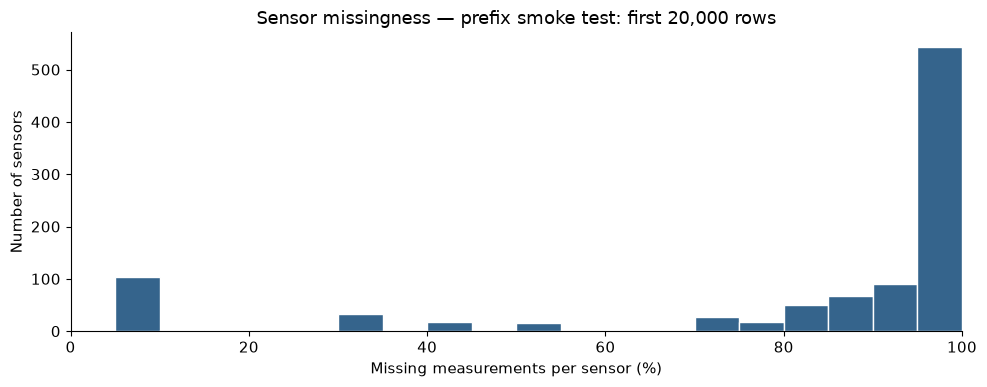

In [3]:
missing_pct = missingness_profile(raw, sensors)
display(missing_pct.describe().to_frame())
display(pd.Series({f'over {cutoff}% missing': int((missing_pct > cutoff).sum())
                   for cutoff in (90, 95, 99)}, name='sensor_count').to_frame())
fig, ax = plt.subplots()
ax.hist(missing_pct, bins=np.linspace(0, 100, 21), color='#35648c', edgecolor='white')
ax.set(title=f'Sensor missingness — {RUN_SCOPE}', xlabel='Missing measurements per sensor (%)',
       ylabel='Number of sensors', xlim=(0, 100))
plt.tight_layout()
plt.show()

### Within-station and between-station masks

The original comparisons are retained. `L0_S0_F2` and `L0_S0_F4` had identical missingness masks, as did the inspected S24 pairs. S0 and S1 differed on 1,642 parts in the saved full-data output, despite nearly equal marginal missing rates. Equal missing percentages alone therefore do not establish equal masks. This supports investigating production-route structure; it does not prove a formal MCAR/MAR/MNAR mechanism.

In [4]:
pairs = [
    ('L0_S0_F2', 'L0_S0_F4'),
    ('L0_S0_F2', 'L0_S1_F24'),
    ('L0_S0_F2', 'L1_S24_F679'),
    ('L1_S24_F683', 'L1_S24_F679'),
    ('L1_S24_F907', 'L1_S24_F920'),
]
pattern_rows = []
for left, right in pairs:
    mask_left, mask_right = raw[left].isna(), raw[right].isna()
    pattern_rows.append({'sensor_a': left, 'sensor_b': right,
                         'identical_masks': mask_left.equals(mask_right),
                         'different_rows': int((mask_left != mask_right).sum())})
display(pd.DataFrame(pattern_rows))
display(pd.crosstab(raw['L0_S0_F2'].isna(), raw['L0_S1_F24'].isna()))
display(pd.crosstab(raw['L0_S0_F2'].isna(), raw['L1_S24_F679'].isna()))
s24_counts = pd.Series({col: raw[col].count() for col in stations['L1_S24']})
display(s24_counts.describe().to_frame('recorded_values_per_S24_sensor'))
display(pd.concat([s24_counts.nsmallest(5), s24_counts.nlargest(5)]).to_frame('recorded_values'))

,sensor_a,sensor_b,identical_masks,different_rows
0,L0_S0_F2,L0_S0_F4,True,0
1,L0_S0_F2,L0_S1_F24,False,39
2,L0_S0_F2,L1_S24_F679,False,11835
3,L1_S24_F683,L1_S24_F679,True,0
4,L1_S24_F907,L1_S24_F920,True,0


L0_S1_F24,False,True
L0_S0_F2,,
False,11476,19
True,20,8485


L1_S24_F679,False,True
L0_S0_F2,,
False,10,11485
True,350,8155


,recorded_values_per_S24_sensor
count,229.000000
mean,675.048035
std,665.407231
min,168.000000
25%,216.000000
50%,360.000000
75%,1117.000000
max,2277.000000


,recorded_values
L1_S24_F1016,168
L1_S24_F1021,168
L1_S24_F1026,168
L1_S24_F1031,168
L1_S24_F1036,168
L1_S24_F1512,2277
L1_S24_F1514,2277
L1_S24_F1516,2277
L1_S24_F1518,2277
L1_S24_F1565,2277


## 3. Data Cleaning and Preparation

- Keep all parts and sparse sensors in the raw data. Wholesale `dropna()` would discard route information and can alter the class mix.
- Preserve extremes: an IQR flag is a diagnostic, not evidence of a measurement error.
- Do not fill the entire raw frame with means. HGB handles `NaN` directly. For the tree baseline only, a pipeline learns medians on training data and adds missing indicators; station counts also retain availability information. An entirely missing training column stays in the schema.
- Exclude `Id` and `Response` from predictors. `Id` is used only for identity, split auditing and deterministic row ordering.
- Split before any new target-conditioned investigation. Descriptive schema/missingness checks above do not select features or fit preprocessing.

**Important:** changing a random seed cannot erase previous full-data exploration. These 64/16/20 partitions (original 80/20 outer split, then 80/20 development split) enforce computational separation for this experiment, but all conclusions remain exploratory.

In [5]:
y = raw['Response'].to_numpy()
splits = split_rows(y, seed=SEED)
train_rows = splits['train']
validation_rows = splits['validation']
evaluation_rows = splits['exploratory_evaluation']
split_summary = pd.DataFrame([
    {'split': name, 'parts': len(rows), 'defects': int(y[rows].sum()),
     'defect_prevalence': float(y[rows].mean())}
    for name, rows in splits.items()
])
display(split_summary)
np.savez_compressed(RUN_DIR / 'split_ids.npz',
                    **{name: raw['Id'].iloc[rows].to_numpy() for name, rows in splits.items()})

,split,parts,defects,defect_prevalence
0,train,12800,72,0.005625
1,validation,3200,18,0.005625
2,exploratory_evaluation,4000,22,0.005500


## 4. Exploratory Data Analysis

All new target comparisons use **training rows only**. The original availability-gap calculation is preserved: percentage available among defective parts minus percentage available among good parts. Large differences can motivate hypotheses about process routes, but do not establish causation. This univariate criterion can also rank many redundant sensors from the same station.

,availability_difference_pp
L3_S33_F3855,-19.099623
L3_S33_F3857,-19.099623
L3_S33_F3859,-19.099623
L3_S33_F3861,-19.099623
L3_S33_F3863,-19.099623
L3_S33_F3865,-19.099623
L3_S33_F3867,-19.099623
L3_S33_F3869,-19.099623
L3_S33_F3871,-19.099623
L3_S33_F3873,-19.099623


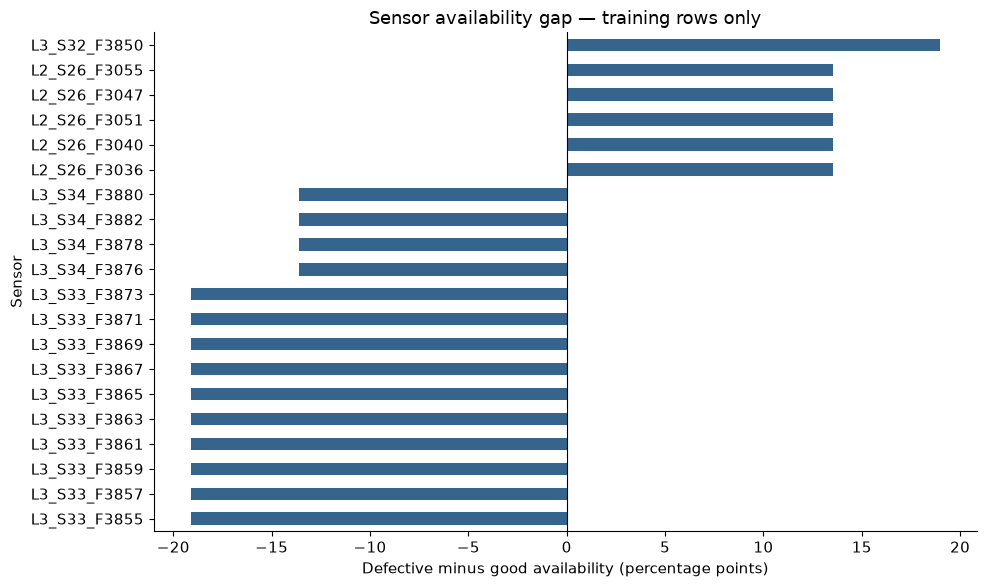

In [6]:
availability_gap = availability_differences(raw, sensors, train_rows)
eda_ranked_sensors = select_sensors(availability_gap, top_n=TOP_N_SENSORS)
display(availability_gap.loc[list(eda_ranked_sensors)].to_frame())
fig, ax = plt.subplots(figsize=(10, 6))
availability_gap.loc[list(eda_ranked_sensors)].sort_values().plot.barh(ax=ax, color='#35648c')
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Sensor availability gap — training rows only',
       xlabel='Defective minus good availability (percentage points)', ylabel='Sensor')
plt.tight_layout()
plt.show()

### Sensor extremes and target relationships

Preserve the original investigation of `L3_S32_F3850`. This sensor was historically chosen after full-data exploration, so even its continued inclusion as an EDA example carries that history. The saved full-data outputs showed 105 IQR flags among 24,543 recorded measurements (~0.428%); none of those 105 parts were defective. That small subgroup is not evidence that extreme values prevent defects.

The code below now computes quantiles and target comparisons on training rows. **No values are removed, clipped or replaced.** The class boxplot hides fliers only for readability; the separate distribution and boxplot include them.

,L3_S32_F3850
count,254.000000
mean,0.004717
std,0.043369
min,-0.127000
25%,-0.019000
50%,0.007000
75%,0.039000
max,0.129000


Training IQR bounds: -0.10599999967962503 0.12600000109523535
Flags / recorded measurements: 2 / 254


Response,0,1
L3_S32_F3850,,
False,237,15
True,2,0


Response,0,1
L3_S32_F3850,,
False,94.047619,5.952381
True,100.000000,0.000000


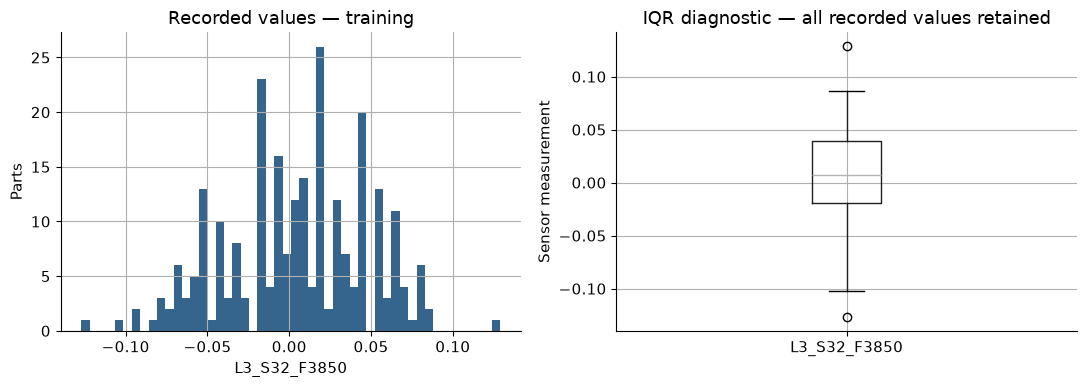

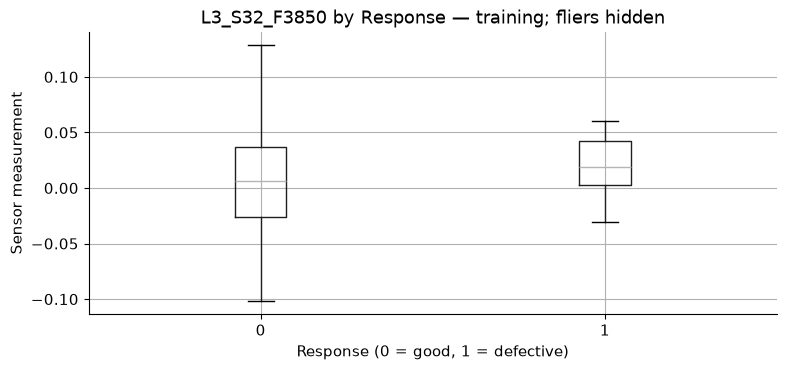

In [7]:
sensor = 'L3_S32_F3850'
eda = raw.loc[:, [sensor, 'Response']].iloc[train_rows]
q1, q3 = eda[sensor].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = (eda[sensor] < lower) | (eda[sensor] > upper)
recorded = eda[sensor].notna()
display(eda[sensor].describe().to_frame())
print('Training IQR bounds:', lower, upper)
print('Flags / recorded measurements:', int(outliers.sum()), '/', int(recorded.sum()))
outlier_table = pd.crosstab(outliers[recorded], eda.loc[recorded, 'Response'])
display(outlier_table)
display(outlier_table.div(outlier_table.sum(axis=1), axis=0).mul(100))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
eda[sensor].hist(bins=50, ax=axes[0], color='#35648c')
axes[0].set(title='Recorded values — training', xlabel=sensor, ylabel='Parts')
eda.boxplot(column=sensor, ax=axes[1])
axes[1].set(title='IQR diagnostic — all recorded values retained', ylabel='Sensor measurement')
plt.tight_layout()
plt.show()
eda.boxplot(column=sensor, by='Response', figsize=(8, 4), showfliers=False)
plt.title(f'{sensor} by Response — training; fliers hidden')
plt.suptitle('')
plt.xlabel('Response (0 = good, 1 = defective)')
plt.ylabel('Sensor measurement')
plt.tight_layout()
plt.show()

## 5. Feature Engineering

Retain total recorded measurements per part and counts for every station (50 in the original numeric header). The implementation walks each sensor once with small integer counters and creates a separate compact feature table, avoiding repeated inserts into the large raw frame. It never counts `Id`, `Response`, or its own engineered columns.

Preserve two original sensor-selection ideas: the 20 highest-coverage sensors, and up to five highest-coverage sensors per focus station. Coverage is learned on training rows. **Correction:** the four focus stations are now selected by absolute training-only present/absent failure-rate differences, replacing the historically handpicked S32/S33/S34/S24 list. This can select different stations and cannot be expected to reproduce historical scores. The full sensor-availability ranking in section 4 is diagnostic, not this model selector.

The same frozen sensor header, selected columns, station rule and ordered model columns are used across all partitions and future unlabeled data. Missing sensor columns are rejected; a provided sensor column containing `NaN` is valid. Preserve the original presence-indicator comparison as well.

`S32_only = (L3_S32_count > 0) & (L3_S33_count == 0)` is generated for analysis but absent from **every default candidate**, consistently with original cells 39–55. An opt-in ablation records inclusion explicitly. Total measurement count is retained as a separate ablation; the original station-count baseline is unchanged.

In [8]:
high_coverage_sensors, focus_sensors, focus_stations, training_station_gaps = select_training_sensors(
    raw, sensors, train_rows, top_n=TOP_N_SENSORS, top_stations=4, per_station=5)
selected_sensors = tuple(dict.fromkeys(high_coverage_sensors + focus_sensors))
features = build_features(raw, sensors, selected_sensors, S32_ABSENT_STATIONS)
presence = pd.DataFrame({f'{col}_present': raw[col].notna().astype('uint8')
                         for col in focus_sensors}, index=raw.index)
features = pd.concat([features, presence], axis=1)
station_count_columns = tuple(f'{station}_count' for station in stations)
feature_sets = {
    'station_counts': station_count_columns,
    'station_counts_plus_total': station_count_columns + ('measurement_count',),
    'station_counts_plus_high_coverage': station_count_columns + high_coverage_sensors,
    'station_counts_plus_focus_values': station_count_columns + focus_sensors,
    'station_counts_plus_focus_presence': station_count_columns + tuple(presence.columns),
}
if INCLUDE_S32_ABLATION:
    feature_sets['station_counts_plus_focus_values_plus_S32_only'] = (
        station_count_columns + focus_sensors + ('S32_only',))
assert 'Id' not in features and 'Response' not in features
assert features.index.equals(raw.index)
print('Training-selected focus stations:', focus_stations)
print('Compact features:', features.shape)
print('Feature memory GiB:', features.memory_usage(deep=True).sum() / 1024**3)
display(pd.DataFrame([
    {'feature_set': name, 'columns': len(cols), 'S32_only': 'S32_only' in cols}
    for name, cols in feature_sets.items()
]))

Training-selected focus stations: ('L3_S32', 'L3_S33', 'L3_S34', 'L3_S38')
Compact features: (20000, 98)
Feature memory GiB: 0.004619482904672623


,feature_set,columns,S32_only
0,station_counts,50,False
1,station_counts_plus_total,51,False
2,station_counts_plus_high_coverage,70,False
3,station_counts_plus_focus_values,63,False
4,station_counts_plus_focus_presence,63,False


### Station coverage and measurement counts

Coverage means **at least one recorded numeric measurement at that station**. It is a proxy for route participation, not proof of a station visit. The saved full-data S24 coverage was 15.5208%, even though individual sensors could be much sparser. Training failure rates below include group denominators so small groups are visible.

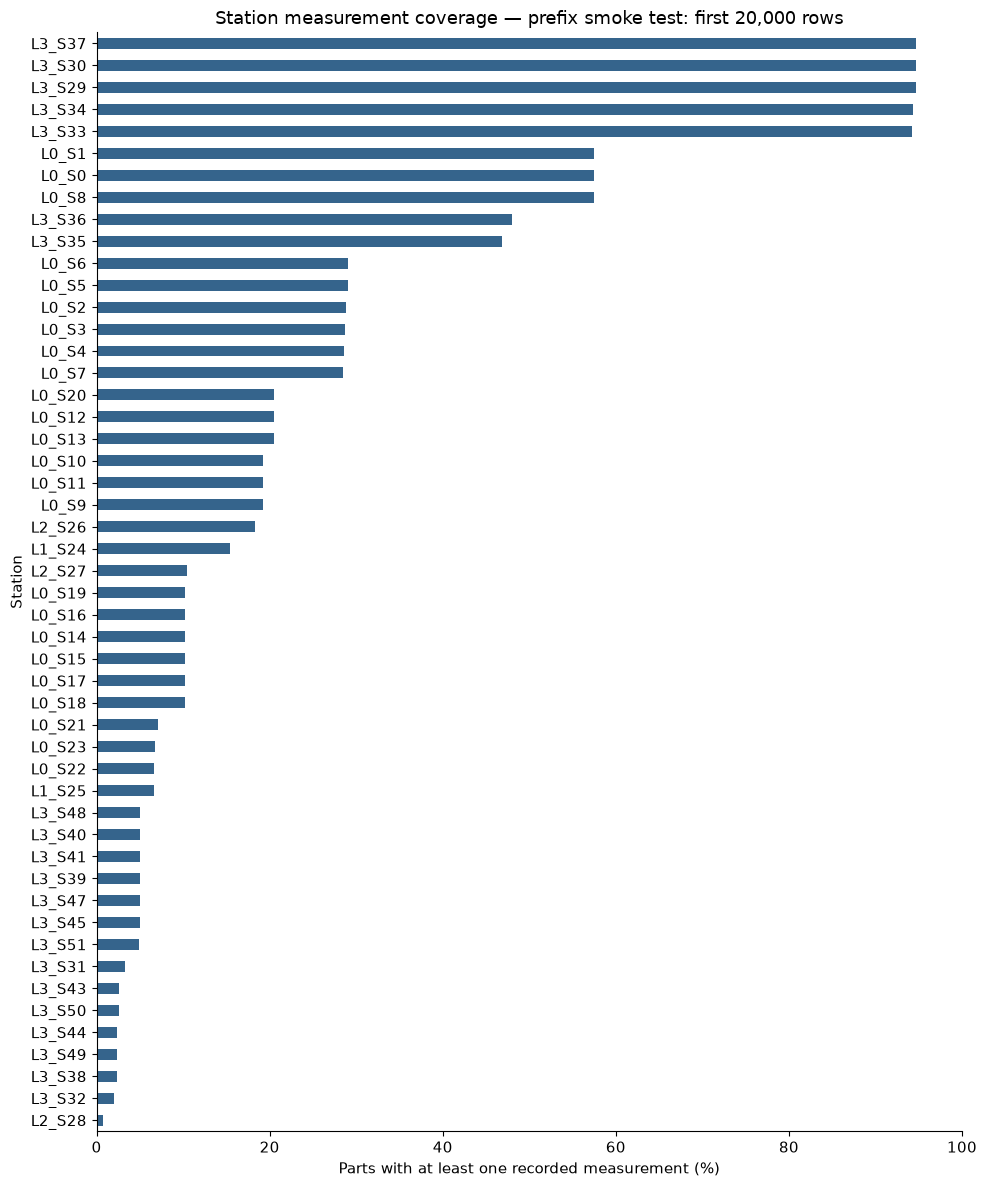

,count,mean,std,min,25%,50%,75%,max
Response,,,,,,,,
0,12728.0,182.686361,25.993955,0.0,160.0,190.0,204.0,266.0
1,72.0,182.972222,28.328044,54.0,165.5,190.0,204.0,235.0


,parts,defects,failure_rate
measurement_count,,,
"(-1.0, 50.0]",29,0,0.000000
"(50.0, 100.0]",4,1,0.250000
"(100.0, 150.0]",739,4,0.005413
"(150.0, 200.0]",8763,45,0.005135
"(200.0, 250.0]",3247,22,0.006775
"(250.0, 400.0]",18,0,0.000000


,station,recorded,parts,defects,failure_rate
48,L1_S24,False,10789,52,0.004820
49,L1_S24,True,2011,20,0.009945
64,L3_S32,False,12546,57,0.004543
65,L3_S32,True,254,15,0.059055
66,L3_S33,False,769,18,0.023407
67,L3_S33,True,12031,54,0.004488
68,L3_S34,False,757,14,0.018494
69,L3_S34,True,12043,58,0.004816


Response                       0   1
L3_S32_count L3_S33_count           
False        False           691   3
             True          11798  54
True         False            60  15
             True            179   0

Response                            0          1
L3_S32_count L3_S33_count                       
False        False          99.567723   0.432277
             True           99.544381   0.455619
True         False          80.000000  20.000000
             True          100.000000   0.000000

In [9]:
station_count_columns = [f'{station}_count' for station in stations]
coverage = pd.Series({station: (features[f'{station}_count'] > 0).mean() * 100
                      for station in stations}).sort_values()
fig, ax = plt.subplots(figsize=(10, 12))
coverage.plot.barh(ax=ax, color='#35648c')
ax.set(title=f'Station measurement coverage — {RUN_SCOPE}',
       xlabel='Parts with at least one recorded measurement (%)', ylabel='Station', xlim=(0, 100))
plt.tight_layout()
plt.show()
train_counts = pd.DataFrame({'measurement_count': features['measurement_count'].iloc[train_rows],
                             'Response': y[train_rows]})
display(train_counts.groupby('Response')['measurement_count'].describe())
# The original upper limit of 400 is extended to infinity so no future row is lost.
bins = pd.cut(train_counts['measurement_count'], [-1, 50, 100, 150, 200, 250, 400, np.inf])
count_rates = train_counts.groupby(bins, observed=True)['Response'].agg(['count', 'sum', 'mean'])
count_rates.columns = ['parts', 'defects', 'failure_rate']
display(count_rates)
station_rates = []
for station in stations:
    present = features[f'{station}_count'].iloc[train_rows].to_numpy() > 0
    for status in (False, True):
        mask = present == status
        station_rates.append({'station': station, 'recorded': status, 'parts': int(mask.sum()),
                              'defects': int(y[train_rows][mask].sum()),
                              'failure_rate': float(y[train_rows][mask].mean()) if mask.any() else None})
station_rates = pd.DataFrame(station_rates)
display(station_rates[station_rates['station'].isin(['L1_S24', 'L3_S32', 'L3_S33', 'L3_S34'])])
station_rates.to_csv(RUN_DIR / 'training_station_rates.csv', index=False)
s32 = features['L3_S32_count'].iloc[train_rows] > 0
s33 = features['L3_S33_count'].iloc[train_rows] > 0
route_table = pd.crosstab([s32, s33], raw['Response'].iloc[train_rows])
display(route_table)
display(route_table.div(route_table.sum(axis=1), axis=0).mul(100))

## 6. Modeling

Preserve the original tree (`max_depth=5`, `min_samples_leaf=200`, balanced weights) and HGB grid (7/15/31 leaves, learning rates 0.05/0.1, 100 iterations, balanced weights). Compare the original station-count baseline, the added total-count ablation, high-coverage sensor values, focus-station values, and focus-sensor presence. Unlike the sequential original experiments, all declared candidates are compared on the same validation rows.

Models train on the 64% training partition. Median imputation is inside the tree pipeline when sensor values are included; HGB keeps missing values. Scaling is unnecessary for these trees. **Deliberate change:** HGB early stopping is disabled instead of the original automatic internal split, making the 100-iteration procedure explicit. This changes the training procedure and may change metrics.

Choose the candidate with highest **validation AP** (ties keep declaration order). No evaluation labels enter model/feature selection. The selected estimator is **not refit** on train+validation, so its validation-based threshold applies to the same fitted model. Repeated validation tuning would still overfit this small positive class.

,feature_set,model,feature_count,includes_S32_only,validation_average_precision
20,station_counts_plus_high_coverage,hgb_leaves_31_lr_0.1,70,False,0.195198
19,station_counts_plus_high_coverage,hgb_leaves_31_lr_0.05,70,False,0.193744
18,station_counts_plus_high_coverage,hgb_leaves_15_lr_0.1,70,False,0.190723
17,station_counts_plus_high_coverage,hgb_leaves_15_lr_0.05,70,False,0.168061
16,station_counts_plus_high_coverage,hgb_leaves_7_lr_0.1,70,False,0.165365
6,station_counts,hgb_leaves_31_lr_0.1,50,False,0.150861
34,station_counts_plus_focus_presence,hgb_leaves_31_lr_0.1,63,False,0.150861
24,station_counts_plus_focus_values,hgb_leaves_15_lr_0.05,63,False,0.135849
4,station_counts,hgb_leaves_15_lr_0.1,50,False,0.132738
32,station_counts_plus_focus_presence,hgb_leaves_15_lr_0.1,63,False,0.132738


Selected: hgb_leaves_31_lr_0.1 / station_counts_plus_high_coverage


,threshold,precision,recall,f1,tn,fp,fn,tp
0,0.005,0.011677,0.611111,0.022917,2251,931,7,11
1,0.010,0.012821,0.444444,0.024922,2566,616,10,8
2,0.020,0.019802,0.444444,0.037915,2786,396,10,8
3,0.050,0.033149,0.333333,0.060302,3007,175,12,6
4,0.100,0.053191,0.277778,0.089286,3093,89,13,5
5,0.500,0.187500,0.166667,0.176471,3169,13,15,3
6,0.600,0.250000,0.166667,0.200000,3173,9,15,3
7,0.700,0.333333,0.166667,0.222222,3176,6,15,3
8,0.800,0.428571,0.166667,0.240000,3178,4,15,3
9,0.900,0.428571,0.166667,0.240000,3178,4,15,3


,capacity_requested,inspected,capacity_actual,precision,recall,f1,tn,fp,fn,tp,lift
0,0.005,16,0.005,0.187500,0.166667,0.176471,3169,13,15,3,33.333333
1,0.010,32,0.010,0.125000,0.222222,0.160000,3154,28,14,4,22.222222
2,0.020,64,0.020,0.078125,0.277778,0.121951,3123,59,13,5,13.888889
3,0.050,160,0.050,0.037500,0.333333,0.067416,3028,154,12,6,6.666667
4,0.100,320,0.100,0.025000,0.444444,0.047337,2870,312,10,8,4.444444


Validation-selected score threshold: 0.8
Primary inspection capacity fixed in advance: 0.01


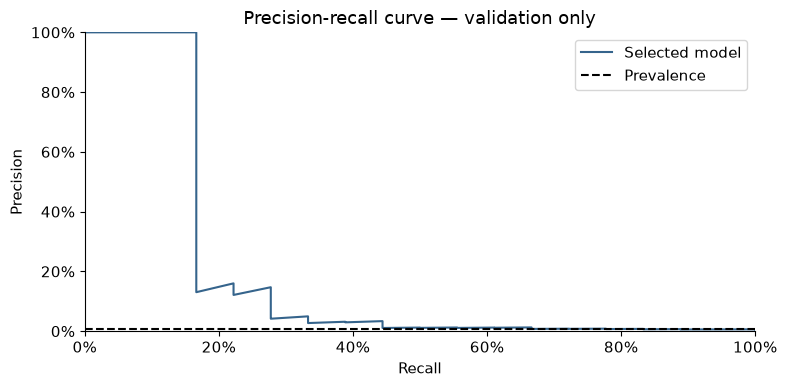

In [10]:
with threadpool_limits(limits=4):
    comparison, best = compare_models(features, y, splits, feature_sets, seed=SEED)
display(comparison.sort_values('validation_average_precision', ascending=False))
print('Selected:', best['model'], '/', best['feature_set'])
comparison.to_csv(RUN_DIR / 'validation_comparison.csv', index=False)

validation_thresholds = threshold_table(y[validation_rows], best['validation_scores'], THRESHOLDS)
display(validation_thresholds)
# F1 is an explicit illustrative rule, not an estimate of factory cost/benefit.
chosen_threshold = float(validation_thresholds.loc[validation_thresholds['f1'].idxmax(), 'threshold'])
validation_capacity = pd.DataFrame([
    capacity_metrics(y[validation_rows], best['validation_scores'], capacity)
    for capacity in CAPACITIES
])
display(validation_capacity)
print('Validation-selected score threshold:', chosen_threshold)
print('Primary inspection capacity fixed in advance:', PRIMARY_CAPACITY)
precision, recall, _ = precision_recall_curve(y[validation_rows], best['validation_scores'])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(recall, precision, color='#35648c', label='Selected model')
ax.axhline(y[validation_rows].mean(), color='black', linestyle='--', label='Prevalence')
ax.set(title='Precision-recall curve — validation only', xlabel='Recall', ylabel='Precision',
       xlim=(0, 1), ylim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.tight_layout()
plt.show()

## 7. Model Evaluation

The next cell evaluates the selected configuration once on the **exploratory evaluation** partition. This is a code-isolated partition, not independent evidence after historical full-data exploration. Do not choose another model or threshold based on these results and continue calling it a holdout.

AP summarizes precision over recall increments; the constant-score AP baseline is prevalence. A score threshold and an inspection budget are distinct policies. At 1% capacity, inspect `ceil(0.01 × n)` rows by descending score; ties retain original input order (independent of labels). Report actual capacity because rounding matters on small samples. Uncalibrated scores, especially from a balanced tree, should not be interpreted as defect probabilities.

In [11]:
with threadpool_limits(limits=4):
    evaluation_scores = best['estimator'].predict_proba(
        features.loc[:, best['columns']].iloc[evaluation_rows])[:, 1]
evaluation_y = y[evaluation_rows]
evaluation_ap = float(average_precision_score(evaluation_y, evaluation_scores))
evaluation_threshold_metrics = classification_metrics(evaluation_y, evaluation_scores >= chosen_threshold)
evaluation_capacity_metrics = capacity_metrics(evaluation_y, evaluation_scores, PRIMARY_CAPACITY)
print('SCOPE:', RUN_SCOPE, '| exploratory evaluation only')
print('Average Precision:', f'{evaluation_ap:.4%}')
print('Constant-score AP baseline:', f'{evaluation_y.mean():.4%}')
display(pd.DataFrame([
    {'policy': f'score >= {chosen_threshold:g}', **evaluation_threshold_metrics},
    {'policy': f'top {PRIMARY_CAPACITY:.1%}', **evaluation_capacity_metrics},
]))
cm = np.array([[evaluation_capacity_metrics['tn'], evaluation_capacity_metrics['fp']],
               [evaluation_capacity_metrics['fn'], evaluation_capacity_metrics['tp']]])
display(pd.DataFrame(cm, index=['Actual good', 'Actual defective'],
                     columns=['Not inspected', 'Inspected']))

SCOPE: prefix smoke test: first 20,000 rows | exploratory evaluation only
Average Precision: 4.6802%
Constant-score AP baseline: 0.5500%


,policy,precision,recall,f1,tn,fp,fn,tp,capacity_requested,inspected,capacity_actual,lift
0,score >= 0.8,0.2,0.090909,0.125000,3970,8,20,2,NaN,NaN,NaN,NaN
1,top 1.0%,0.1,0.181818,0.129032,3942,36,18,4,0.01,40.0,0.01,18.181818


,Not inspected,Inspected
Actual good,3942,36
Actual defective,18,4


### Gains and lift

Gains show the share of all defective parts found as inspection capacity increases. Lift divides that recall by the inspected population fraction; random ranking has expected lift 1. These curves describe this run's selected model and evaluation partition only. They are not factory profit estimates or confidence intervals.

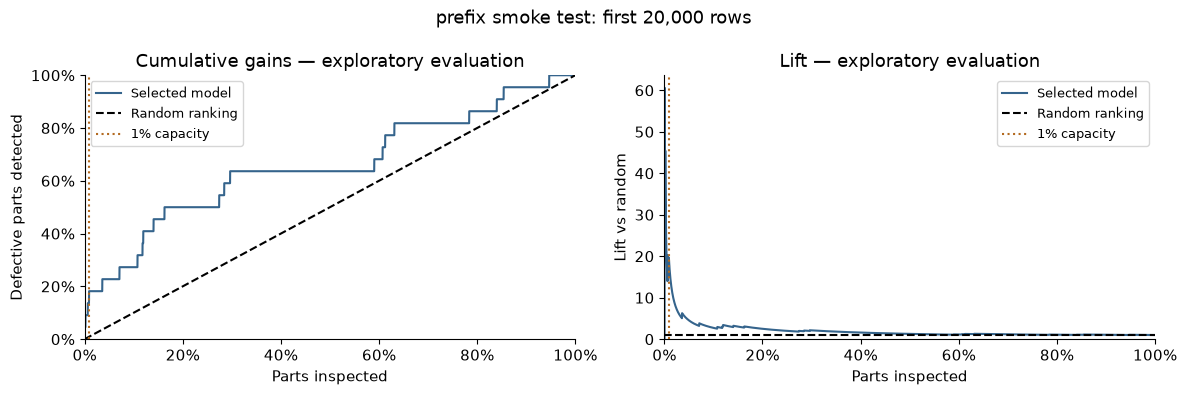

In [12]:
fraction, gain, lift = gains_curve(evaluation_y, evaluation_scores)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.r_[0, fraction], np.r_[0, gain], color='#35648c', label='Selected model')
axes[0].plot([0, 1], [0, 1], '--', color='black', label='Random ranking')
axes[0].set(title='Cumulative gains — exploratory evaluation',
            xlabel='Parts inspected', ylabel='Defective parts detected', xlim=(0, 1), ylim=(0, 1))
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].plot(fraction, lift, color='#35648c', label='Selected model')
axes[1].axhline(1, linestyle='--', color='black', label='Random ranking')
axes[1].set(title='Lift — exploratory evaluation', xlabel='Parts inspected', ylabel='Lift vs random', xlim=(0, 1), ylim=(0, None))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
for ax in axes:
    ax.axvline(PRIMARY_CAPACITY, color='#b36a20', linestyle=':', label='1% capacity')
    ax.legend(fontsize=9)
fig.suptitle(RUN_SCOPE)
plt.tight_layout()
fig.savefig(RUN_DIR / 'gains_lift.png', dpi=150, bbox_inches='tight')
plt.show()

### Save experiment provenance and inference contract

Each run gets its own ignored artifacts directory: split IDs, model-selection table, training summaries, feature schema, fitted model, source/code metadata and newly computed metrics. The source path/size/mtime and loaded ID digest identify local input context; they are **not a full CSV content checksum**. Keep the same input file and environment when reproducing a run. Do not upload raw data, split IDs or model bundles by accident.

For future data, load the numeric schema and call `bosch.predict_unseen(bundle, raw_unlabeled)`. This checks raw columns and applies the saved transformation and model column order. Use only trusted joblib files.

In [13]:
bundle = {'estimator': best['estimator'], 'columns': best['columns'],
          'sensors': sensors, 'selected_sensors': selected_sensors,
          's32_absent_stations': S32_ABSENT_STATIONS, 'threshold': chosen_threshold,
          'presence_sensors': focus_sensors}
joblib.dump(bundle, RUN_DIR / 'model.joblib')
source_stat = DATA_PATH.stat()
manifest = {
    'run_id': RUN_ID, 'scope': RUN_SCOPE, 'requested_nrows': N_ROWS,
    'loaded_rows': len(raw), 'seed': SEED, 'split_fractions': [0.64, 0.16, 0.2],
    'source': {'path': str(DATA_PATH), 'bytes': source_stat.st_size,
               'mtime_ns': source_stat.st_mtime_ns,
               'loaded_ids_sha256': hashlib.sha256(raw['Id'].to_numpy().tobytes()).hexdigest()},
    'python': platform.python_version(),
    'versions': {name: version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'joblib']},
    'code_sha256': {name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest()
                    for name in ['bosch.py', 'requirements.txt', 'requirements.lock']},
    'notebook_source_sha256': hashlib.sha256(json.dumps([
        {'cell_type': cell['cell_type'], 'source': ''.join(cell['source'])}
        for cell in json.loads((ROOT / 'explore.ipynb').read_text())['cells']
    ], sort_keys=True).encode()).hexdigest(),
    'top_n_sensors': TOP_N_SENSORS, 'sensor_schema': sensors,
    'selected_sensors': selected_sensors, 'feature_sets': feature_sets,
    'high_coverage_sensors': high_coverage_sensors, 'focus_sensors': focus_sensors,
    'training_selected_focus_stations': focus_stations, 'include_S32_ablation': INCLUDE_S32_ABLATION,
    's32_absent_stations': S32_ABSENT_STATIONS,
    'selected_model': best['model'], 'selected_feature_set': best['feature_set'],
    'model_columns': best['columns'],
    'candidate_parameters': {name: model.get_params() for name, model in model_candidates(SEED)},
    'threshold_grid': THRESHOLDS, 'threshold_selection': 'maximum validation F1; first tie wins',
    'chosen_threshold': chosen_threshold, 'capacities_on_validation': CAPACITIES,
    'primary_capacity': PRIMARY_CAPACITY, 'tie_policy': 'stable input order',
    'split_summary': split_summary.to_dict(orient='records'),
    'validation_average_precision': best['validation_average_precision'],
    'exploratory_evaluation_average_precision': evaluation_ap,
    'exploratory_evaluation_threshold': evaluation_threshold_metrics,
    'exploratory_evaluation_capacity': evaluation_capacity_metrics,
    'independent_holdout': False,
}
(RUN_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2, default=str) + '\n')
print('Saved run:', RUN_DIR.relative_to(ROOT))

Saved run: artifacts/20261029T125911739576Z


### Historical exploratory results preserved from saved outputs

These numbers appear in the archived notebook (zero-based cell 49 for validation AP; cell 55 for test AP/precision/recall). They match the project brief. They have **not** been rerun by this refactor and must stay separate from every newly computed table and plot above.

| Historical exploratory metric | Reported approximate value |
|---|---:|
| Validation Average Precision | 5.42% |
| Previously inspected test Average Precision | 4.35% |
| Test precision, highest-risk 1% inspected | 8.79% |
| Test recall, highest-risk 1% inspected | 15.12% |

The archived best experiment used 50 station counts plus 15 sensor values from the historically chosen S32/S33/S34/S24 stations, excluded `S32_only`, and used HGB with 15 leaves, learning rate 0.1, 100 maximum iterations and balanced weights. The final model was refit on the outer 80% training split. Original inspection counts used floor rounding and an unspecified tie ordering. These saved scores are exploratory: the test partition had already been inspected and the focus-station choice used full-data target evidence.

## 8. Conclusions and Limitations

**Established in the saved investigation:** sensor missingness is highly structured; selected sensors within a station share masks; route coverage and individual-sensor coverage differ; extreme values require investigation rather than automatic removal. These findings motivate reusable measurement counts and explicit missingness treatment.

**What the extension establishes:** a reviewable experiment definition, training-only supervised ranking and imputation, consistent feature columns, a declared validation selection rule, and separate threshold/capacity evaluation. Its computed scores apply only to the run scope printed above. A successful prefix execution verifies software flow, not full-data performance or representativeness.

**Remaining limits:** historical human selection leakage cannot be repaired retroactively; the original test set was already inspected; random row splits do not address time drift, batches or repeated processes; sensor availability at prediction time is unverified; sparse subgroups and few defects make estimates unstable; the availability-gap selector can choose redundant sensors and miss measurement-value signals. No formal uncertainty interval or cost-benefit analysis has been performed.

**Before stronger claims:** review the preserved S32/S33 definition and updated station-selection rule; freeze an operational prediction timestamp and process-valid feature set; acquire genuinely new, untouched parts, ideally evaluated in time/batch order; freeze selection and threshold decisions before accessing their labels. Nested CV with selection inside each fold can characterize development variability, but cannot erase the historical exploration of this dataset.

Lecture alignment: missingness/outlier diagnostics (4–5), visual EDA (6), reusable features (7), model complexity and train/validation/evaluation separation (8–9), threshold/cost reasoning (10–11), gains and lift (12). See [docs/audit.md](docs/audit.md) for the local materials inspected, preservation map and unresolved provenance.